In [32]:
import csv
from sklearn.svm import LinearSVC
from nltk.classify import SklearnClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_fscore_support
import numpy as np
from sklearn import metrics
import matplotlib.pyplot as plt

In [33]:
def load_data(path):
    """Load data from a tab-separated file and append it to raw_data."""
    with open(path, encoding='utf-8', errors='ignore') as f:
        reader = csv.reader(f, delimiter='\t')
        for line in reader:
            (label, text) = parse_data_line(line)
            raw_data.append((text, label))

def split_and_preprocess_data(percentage):
    """Split the data between train_data and test_data according to the percentage
    and performs the preprocessing."""
    num_samples = len(raw_data)
    num_training_samples = int((percentage * num_samples))
    for (text, label) in raw_data[:num_training_samples]:
        train_data.append((to_feature_vector(pre_process(text)),label))
    for (text, label) in raw_data[num_training_samples:]:
        test_data.append((to_feature_vector(pre_process(text)),label))
        
def parse_data_line(data_line):
    """Return a tuple of the label and the statement"""
    return (data_line[1], data_line[2])

def pre_process(text):
    """Return a list of tokens"""
    return text.split()

In [34]:
# test
text = "RT @colonelkickhead: Another bloody instant restaurant week?!?! Seriously! They just jumped the shark riding two other sharks powered by sh…"
pre_process(text)

['RT',
 '@colonelkickhead:',
 'Another',
 'bloody',
 'instant',
 'restaurant',
 'week?!?!',
 'Seriously!',
 'They',
 'just',
 'jumped',
 'the',
 'shark',
 'riding',
 'two',
 'other',
 'sharks',
 'powered',
 'by',
 'sh…']

# Question 1: Basic Feature Extraction 


In [35]:

global_feature_dict = {}  # A global dictionary of features

def to_feature_vector(tokens):
    """Convert a list of tokens into a feature vector.
    
    METHOD: Binary Bag-of-Words Representation
    
    This function creates a dictionary-based feature vector where:
    - Each unique token (word) from the input becomes a feature (dictionary key)
    - Each feature has a binary value of 1 (indicating presence)
    - Tokens not in the text have implicit value 0 (not included in dictionary)
    
    This binary representation captures whether words appear in the text,
    rather than how many times they appear (frequency). This approach works
    well for sentiment analysis as the presence of certain words (like "love"
    or "hate") is often more important than their frequency.
    
    The global_feature_dict is also updated to track all unique tokens
    seen across the entire dataset, which helps understand vocabulary size.
    
    Args:
        tokens: List of strings (words) from pre_process()
    
    Returns:
        Dictionary with tokens as keys and 1 as values
        Example: ['good', 'movie', 'good'] -> {'good': 1, 'movie': 1}
    """
    global global_feature_dict
    feature_vector = {}
    
    for token in tokens:
        feature_vector[token] = 1  # Binary: 1 if present, 0 (implicit) if absent
        
        # Update global feature dictionary to track vocabulary
        if token not in global_feature_dict:
            global_feature_dict[token] = 0
        global_feature_dict[token] += 1
    
    return feature_vector

In [36]:
# TRAINING AND VALIDATING OUR CLASSIFIER
def train_classifier(data):
    print("Training Classifier...")
    pipeline = Pipeline([('svc', LinearSVC(max_iter=10000))])
    return SklearnClassifier(pipeline).train(data)

# Question 2: Cross-validation 

In [37]:
def cross_validate(dataset, folds):
    """Perform k-fold cross-validation on the dataset.
    
    METHOD: K-Fold Cross-Validation
    
    This function divides the dataset into k equal-sized folds and performs
    k rounds of training and testing:
    - In each round, one fold is used for testing
    - The remaining (k-1) folds are used for training
    - This ensures every sample is used for testing exactly once
    
    For each fold:
    1. Split data into train (all except current fold) and test (current fold)
    2. Train classifier on training portion
    3. Predict labels for test portion
    4. Calculate precision, recall, and F1-score
    
    Finally, compute and return the average scores across all folds.
    
    Args:
        dataset: List of (feature_vector, label) tuples
        folds: Number of folds (typically 10)
    
    Returns:
        Tuple of (avg_precision, avg_recall, avg_f1)
    """
    results = []
    fold_size = int(len(dataset) / folds) + 1
    
    for i in range(0, len(dataset), fold_size):
        # Define the test fold
        test_fold = dataset[i:i+fold_size]
        
        # Define the training folds (everything except test fold)
        train_fold = dataset[:i] + dataset[i+fold_size:]
        
        print(f"Fold starting at items {i} - {i+fold_size}")
        
        # Train classifier on training folds
        classifier = train_classifier(train_fold)
        
        # Get true labels and predictions for test fold
        test_true = [label for (features, label) in test_fold]
        test_features = [features for (features, label) in test_fold]
        test_pred = predict_labels(test_features, classifier)
        
        # Calculate metrics for this fold
        scores = precision_recall_fscore_support(test_true, test_pred, average='weighted')
        precision, recall, f1 = scores[0], scores[1], scores[2]
        
        results.append((precision, recall, f1))
        print(f"  Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")
    
    # Calculate average scores across all folds
    avg_precision = sum(r[0] for r in results) / len(results)
    avg_recall = sum(r[1] for r in results) / len(results)
    avg_f1 = sum(r[2] for r in results) / len(results)
    
    print("\n" + "="*60)
    print("CROSS-VALIDATION RESULTS (Average across all folds)")
    print("="*60)
    print(f"Average Precision: {avg_precision:.4f}")
    print(f"Average Recall:    {avg_recall:.4f}")
    print(f"Average F1-Score:  {avg_f1:.4f}")
    print("="*60)
    
    return (avg_precision, avg_recall, avg_f1)


In [38]:
# PREDICTING LABELS GIVEN A CLASSIFIER
def predict_labels(samples, classifier):
    """Assuming preprocessed samples, return their predicted labels from the classifier model."""
    return classifier.classify_many(samples)

def predict_label_from_raw(sample, classifier):
    """Assuming raw text, return its predicted label from the classifier model."""
    return classifier.classify(to_feature_vector(pre_process(sample)))


In [40]:
# MAIN

# loading reviews
# initialize global lists that will be appended to by the methods below
raw_data = []          # the filtered data from the dataset file
train_data = []        # the pre-processed training data as a percentage of the total dataset
test_data = []         # the pre-processed test data as a percentage of the total dataset


# references to the data files
data_file_path = 'sentiment-dataset 2.tsv'

# Do the actual stuff (i.e. call the functions we've made)
# We parse the dataset and put it in a raw data list
print("Now %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Preparing the dataset...",sep='\n')

load_data(data_file_path) 

# We split the raw dataset into a set of training data and a set of test data (80/20)
# You do the cross validation on the 80% (training data)
# We print the number of training samples and the number of features before the split
print("Now %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Preparing training and test data...",sep='\n')

split_and_preprocess_data(0.8)

# We print the number of training samples and the number of features after the split
print("After split, %d rawData, %d trainData, %d testData" % (len(raw_data), len(train_data), len(test_data)),
      "Training Samples: ", len(train_data), "Features: ", len(global_feature_dict), sep='\n')


Now 0 rawData, 0 trainData, 0 testData
Preparing the dataset...
Now 33540 rawData, 0 trainData, 0 testData
Preparing training and test data...
After split, 33540 rawData, 26832 trainData, 6708 testData
Training Samples: 
26832
Features: 
104038


In [41]:
cross_validate(train_data, 10)  # will work and output overall performance of p, r, f-score when cv implemented

Fold starting at items 0 - 2684
Training Classifier...
  Precision: 0.8320, Recall: 0.8346, F1: 0.8329
Fold starting at items 2684 - 5368
Training Classifier...
  Precision: 0.8323, Recall: 0.8364, F1: 0.8341
Fold starting at items 5368 - 8052
Training Classifier...
  Precision: 0.7918, Recall: 0.7917, F1: 0.7917
Fold starting at items 8052 - 10736
Training Classifier...
  Precision: 0.8214, Recall: 0.8197, F1: 0.8193
Fold starting at items 10736 - 13420
Training Classifier...
  Precision: 0.8289, Recall: 0.8312, F1: 0.8292
Fold starting at items 13420 - 16104
Training Classifier...
  Precision: 0.8423, Recall: 0.8443, F1: 0.8421
Fold starting at items 16104 - 18788
Training Classifier...
  Precision: 0.8355, Recall: 0.8376, F1: 0.8361
Fold starting at items 18788 - 21472
Training Classifier...
  Precision: 0.8258, Recall: 0.8286, F1: 0.8257
Fold starting at items 21472 - 24156
Training Classifier...
  Precision: 0.8384, Recall: 0.8405, F1: 0.8388
Fold starting at items 24156 - 26840
T

(0.8286815927108231, 0.8304664857796519, 0.8288550081319425)

# Question 3: Error Analysis

In [47]:
from sklearn.model_selection import KFold

print("\nPreparing Data Split")

kf = KFold(n_splits=5, shuffle=True, random_state=42)
folds = list(kf.split(train_data))

train_idx, test_idx = folds[0]

Q3_train = [train_data[i] for i in train_idx]
Q3_test  = [train_data[i] for i in test_idx]

X_test_features = [item[0] for item in Q3_test]
y_test_labels   = [item[1] for item in Q3_test]

print("Training Samples:", len(Q3_train))
print("Testing Samples:", len(Q3_test))



Preparing Data Split
Training Samples: 21465
Testing Samples: 5367


In [54]:
def confusion_matrix_heatmap(y_true, y_pred, labels):
    """
    Create and display a confusion matrix heatmap
    
    Args:
        y_true: List of true labels
        y_pred: List of predicted labels
        labels: List of label names
    """
    # Create confusion matrix
    cm = metrics.confusion_matrix(y_true, y_pred, labels=labels)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Create heatmap
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    
    # Add colorbar
    plt.colorbar(im)
    
    # Set title and labels
    ax.set_title('Confusion Matrix')
    tick_marks = np.arange(len(labels))
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    
    # Rotate x-axis labels
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    
    # Add text annotations to cells
    thresh = cm.max() / 2.
    for i, j in np.ndindex(cm.shape):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")
    
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')
    
    # Adjust layout to prevent label cutoff
    plt.tight_layout()
    


Training Classifier
Training Classifier...
Training Classifier... Done.

Predicting on Test Samples


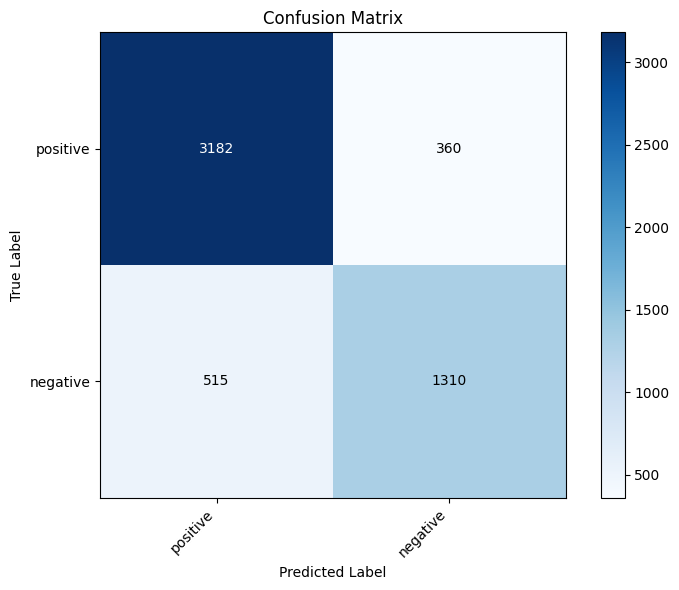

In [55]:
print("\nTraining Classifier")
Q3_classifier = train_classifier(Q3_train)
print("Training Classifier... Done.")

print("\nPredicting on Test Samples")
Q3_preds = predict_labels(X_test_features, Q3_classifier)

confusion_matrix_heatmap(y_test_labels, Q3_preds, labels=['positive','negative'])

In [50]:
print("\nError Analysis Metrics (Percentage Rates)")

total_test = len(Q3_preds)
total_errors = sum(1 for t, p in zip(y_test_labels, Q3_preds) if t != p)

false_positive = 0
false_negative = 0

for (feat_dict, true_label), pred_label in zip(Q3_test, Q3_preds):
    if true_label == 'negative' and pred_label == 'positive':
        false_positive += 1
    if true_label == 'positive' and pred_label == 'negative':
        false_negative += 1

accuracy = (total_test - total_errors) / total_test * 100
fp_rate = (false_positive / total_test) * 100
fn_rate = (false_negative / total_test) * 100

print(f"Total Test Samples: {total_test}")
print(f"Total Errors: {total_errors}")
print(f"Accuracy: {accuracy:.1f}%")
print(f"False Positives: {false_positive}, False Positive Rate: {fp_rate:.1f}")
print(f"False Negatives: {false_negative}, False Negative Rate: {fn_rate:.1f}")



Error Analysis Metrics (Percentage Rates)
Total Test Samples: 5367
Total Errors: 875
Accuracy: 83.7%
False Positives: 515, False Positive Rate: 9.6
False Negatives: 360, False Negative Rate: 6.7


In [51]:
print("\nFalse Positive Examples (first 10)")
for t in false_positive_examples[:10]:
    print("-", t)

print("\nFalse Negative Examples (first 10)")
for t in false_negative_examples[:10]:
    print("-", t)



False Positive Examples (first 10)
- #ThankYouObama for creating the strongest @republicanparty in almost a century and electing @realDonaldTrump.
- WWE, Hulk Hogan End Tie After Racist Comment: World Wrestling Entertainment Inc (WWE.N) said on Friday it has ... http://t.co/sEeJXZ8b9x
- @Iiamneeson all I can say is that it was very unrealistic. The 1st movie better-storyline, dialogue! And of course \""The Grey\"" thumbs up!
- @elizabethforma Hey Liz, the People are despairing at all this Russian hacking stuff - can you let us know you're working on it?
- Marine Le Pen's dad is a savage. You can tell who in control based on you can't offend > https://t.co/0FfiQnZNsG
- I'm starting to think Kane may just be a one season wonder.
- Its a shame I wont be able to watch the Heat smoke Knicks tomorrow
- listening to Kendrick Lamar.....I don't even want get a hair cut tomorrow!!!
- @CoL_70 Yep, Mavs started 0-4 before racking up 67 wins in 06-07. Of course they also flamed out the 1st round a

# Question 4: Optimising pre-processing and feature extraction

**Note:** it is advisable to implement question 4 in a separate notebook where you further develop the pre-processing and feature extraction functions you implemented above.

In [31]:
# Finally, check the accuracy of your classifier by training on all the traning data
# and testing on the test set
# Will only work once all functions are complete
functions_complete = False  # set to True once you're happy with your methods for cross val
if functions_complete:
    print(test_data[0])   # have a look at the first test data instance
    classifier = train_classifier(train_data)  # train the classifier
    test_true = [t[1] for t in test_data]   # get the ground-truth labels from the data
    test_pred = predict_labels([x[0] for x in test_data], classifier)  # classify the test data to get predicted labels
    final_scores = precision_recall_fscore_support(test_true, test_pred, average='weighted') # evaluate
    print("Done training!")
    print("Precision: %f\nRecall: %f\nF Score:%f" % final_scores[:3])